# 🐝 BeeSafe AI — 02: Chemical Identity Audit + Automated PubChem Verification

## 1. Configuration and imports

Works with your **existing Anaconda/Jupyter kernel**; no new environment. It uses your E: drive location, with an optional `BEESAFE_PROJECT_ROOT` override for portability. `BEESAFE_PUBCHEM_ENABLED=0` disables network lookups for offline runs. Internet access is required for live PubChem verification; successful results are cached for reproducible reruns.

In [1]:
import hashlib
import json
import os
import re
import time
from collections import Counter
from datetime import datetime, timezone
from itertools import combinations
from pathlib import Path
from urllib.parse import quote

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from rdkit import Chem, RDLogger, rdBase

# Suppress verbose RDKit informational messages, not errors.
RDLogger.DisableLog("rdApp.info")

DEFAULT_ROOT = Path(r"E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI")
PROJECT_ROOT = Path(os.environ.get("BEESAFE_PROJECT_ROOT", str(DEFAULT_ROOT)))
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "dataset_final.csv"
AUDIT_DIR = PROJECT_ROOT / "reports" / "chemical_identity_audit"
CACHE_DIR = AUDIT_DIR / "pubchem_api_cache"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Network enabled by default. Set to False if offline.
USE_PUBCHEM = os.environ.get("BEESAFE_PUBCHEM_ENABLED", "1") == "1"
FORCE_REFRESH = False
HTTP_TIMEOUT_SECONDS = 14
MAX_RETRIES = 2
REQUEST_DELAY_SECONDS = 0.60     # < 2 requests per second; PubChem asks <= 5/sec
MAX_NAME_CANDIDATES = 8

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 65)

print("BeeSafe AI — Notebook 02 (automated verification)")
print("RDKit:", rdBase.rdkitVersion)
print("Project path:", PROJECT_ROOT)
print("Raw dataset found:", DATA_PATH.is_file())
print("PubChem live lookup enabled:", USE_PUBCHEM)
print("Report directory:", AUDIT_DIR)

BeeSafe AI — Notebook 02 (automated verification)
RDKit: 2026.09.1
Project path: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI
Raw dataset found: True
PubChem live lookup enabled: True
Report directory: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\chemical_identity_audit


## 2. Load the original dataset and record its checksum

A SHA-256 checksum lets us confirm later that the source file has not changed. `source_row_index` refers to the **zero-based row index in the CSV's data portion**, which makes audit findings traceable.

In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Missing: {DATA_PATH}\nPut dataset_final.csv inside BeeSafe AI/data/raw."
    )

source_checksum_before = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
original_df = pd.read_csv(DATA_PATH)
required_columns = {
    "name", "CID", "CAS", "SMILES", "source", "year",
    "toxicity_type", "herbicide", "fungicide", "insecticide",
    "other_agrochemical", "label", "ppdb_level"
}
missing_columns = required_columns - set(original_df.columns)
if missing_columns:
    raise ValueError(f"Missing expected ApisTox columns: {sorted(missing_columns)}")

work = original_df.copy(deep=True)
work.insert(0, "source_row_index", np.arange(len(work), dtype=int))
work["CID_numeric"] = pd.to_numeric(work["CID"], errors="coerce").astype("Int64")
work["CAS_clean"] = work["CAS"].astype("string").str.strip()

print("Source shape:", original_df.shape)
print("Missing entries:", int(original_df.isna().sum().sum()))
print("Exact duplicate rows:", int(original_df.duplicated().sum()))
print("SHA256:", source_checksum_before)
display(original_df.head(3))

Source shape: (1035, 13)
Missing entries: 0
Exact duplicate rows: 0
SHA256: de4b160a23601a44ac5ec5b23aae95973acba060135630a6df8f73d128baea9e


,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,other_agrochemical,label,ppdb_level
0,Ethanedioic acid,971,144-62-7,O=C(O)C(=O)O,ECOTOX,1832,Contact,0,0,0,0,0,0
1,Para-cymene,7463,99-87-6,Cc1ccc(C(C)C)cc1,BPDB,1833,Other,0,0,0,1,0,1
2,Kieselguhr,24261,61790-53-2,O=[Si]=O,ECOTOX,1833,Contact,0,0,0,0,0,0


## 3. Normalize chemical structures with RDKit (without changing raw SMILES)

- **Canonical SMILES:** normalized notation *with stereochemistry preserved*.
- **Largest fragment:** useful to spot a counterion/salt difference, but not a basis for treating two records as identical.
- No automatic tautomerization, desalinization, uncharging, or replacement of the original structure.

In [3]:
def structure_from_smiles(text):
    out = {"valid_smiles": False, "canonical_smiles": None,
           "largest_fragment_smiles": None, "fragment_count": None}
    if not isinstance(text, str) or not text.strip():
        return out
    try:
        mol = Chem.MolFromSmiles(text)
        if mol is None:
            return out
        parts = Chem.GetMolFrags(mol, asMols=True, sanitizeFrags=True)
        part_strings = [Chem.MolToSmiles(p, canonical=True, isomericSmiles=True) for p in parts]
        # Deterministic: largest heavy-atom fragment; tie-break by canonical SMILES.
        best = max(zip(parts, part_strings), key=lambda pair: (
            pair[0].GetNumHeavyAtoms(), pair[1]
        ))[1]
        return {
            "valid_smiles": True,
            "canonical_smiles": Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True),
            "largest_fragment_smiles": best,
            "fragment_count": len(parts)
        }
    except (ValueError, RuntimeError):
        return out

structures = pd.DataFrame(
    [structure_from_smiles(x) for x in work["SMILES"]],
    index=work.index
)
audit = pd.concat([work, structures], axis=1)

print("Valid RDKit SMILES:", int(audit["valid_smiles"].sum()), "/", len(audit))
print("Invalid or blank SMILES:", int((~audit["valid_smiles"]).sum()))
print("Unique canonical SMILES:", audit["canonical_smiles"].nunique())
print("Unique largest-fragment SMILES:", audit["largest_fragment_smiles"].nunique())
display(audit.loc[:, ["name", "CID", "SMILES", "canonical_smiles", "fragment_count"]].head(5))

Valid RDKit SMILES: 1035 / 1035
Invalid or blank SMILES: 0
Unique canonical SMILES: 1035
Unique largest-fragment SMILES: 984


,name,CID,SMILES,canonical_smiles,fragment_count
0,Ethanedioic acid,971,O=C(O)C(=O)O,O=C(O)C(=O)O,1
1,Para-cymene,7463,Cc1ccc(C(C)C)cc1,Cc1ccc(C(C)C)cc1,1
2,Kieselguhr,24261,O=[Si]=O,O=[Si]=O,1
3,Benzoic acid,243,O=C(O)c1ccccc1,O=C(O)c1ccccc1,1
4,Tetradifon (Ref: ENT 23737),8305,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,1


## 4. Find repeated identifiers and compare each repeated CID pair

Two rows can have the same CID yet different molecules. This notebook explicitly compares those structures and both toxicity-related columns. It **does not assume that a label disagreement means that the measurements are wrong**: the original compound identifiers may be wrong.

In [4]:
def nonempty_duplicate_mask(series):
    s = series.astype("string").str.strip().replace("", pd.NA)
    return s.notna() & s.duplicated(keep=False)

audit["cid_repeated"] = audit["CID_numeric"].notna() & audit["CID_numeric"].duplicated(keep=False)
audit["cas_repeated"] = nonempty_duplicate_mask(audit["CAS_clean"])
audit["canonical_repeated"] = nonempty_duplicate_mask(audit["canonical_smiles"])
audit["largest_fragment_repeated"] = nonempty_duplicate_mask(audit["largest_fragment_smiles"])

pair_rows = []
for cid, group in audit.loc[audit["cid_repeated"]].groupby("CID_numeric"):
    for (_, a), (_, b) in combinations(group.iterrows(), 2):
        pair_rows.append({
            "shared_CID": int(cid),
            "row_1": int(a["source_row_index"]),
            "row_2": int(b["source_row_index"]),
            "name_1": a["name"], "name_2": b["name"],
            "CAS_1": a["CAS"], "CAS_2": b["CAS"],
            "canonical_equal": bool(a["canonical_smiles"] == b["canonical_smiles"]),
            "largest_fragment_equal": bool(a["largest_fragment_smiles"] == b["largest_fragment_smiles"]),
            "label_1": a["label"], "label_2": b["label"],
            "binary_label_conflict": bool(a["label"] != b["label"]),
            "ppdb_1": a["ppdb_level"], "ppdb_2": b["ppdb_level"],
            "ppdb_level_conflict": bool(a["ppdb_level"] != b["ppdb_level"]),
        })

pairs = pd.DataFrame(pair_rows)
for col in ["cid_multiple_structures", "cid_conflicting_labels", "cid_conflicting_ppdb"]:
    audit[col] = False

for cid, group in audit.loc[audit["cid_repeated"]].groupby("CID_numeric"):
    mask = audit["CID_numeric"] == cid
    audit.loc[mask, "cid_multiple_structures"] = group["canonical_smiles"].nunique(dropna=False) > 1
    audit.loc[mask, "cid_conflicting_labels"] = group["label"].nunique(dropna=False) > 1
    audit.loc[mask, "cid_conflicting_ppdb"] = group["ppdb_level"].nunique(dropna=False) > 1

print("Repeated CID groups:", audit.loc[audit["cid_repeated"], "CID_numeric"].nunique())
print("Records with repeated CIDs:", int(audit["cid_repeated"].sum()))
print("Repeated CAS records:", int(audit["cas_repeated"].sum()))
print("Repeated canonical-structure records:", int(audit["canonical_repeated"].sum()))
print("CID pairs with conflicting binary labels:", int(pairs.get("binary_label_conflict", pd.Series(dtype=bool)).sum()))
display(pairs)

Repeated CID groups: 5
Records with repeated CIDs: 10
Repeated CAS records: 0
Repeated canonical-structure records: 0
CID pairs with conflicting binary labels: 2


,shared_CID,row_1,row_2,name_1,name_2,CAS_1,CAS_2,canonical_equal,largest_fragment_equal,label_1,label_2,binary_label_conflict,ppdb_1,ppdb_2,ppdb_level_conflict
0,13836,290,295,Chlormequat,"2-Chloro-N,N,N-trimethylethanaminium chloride (1:1)",7003-89-6,999-81-5,False,True,0,0,False,1,1,False
1,16116,413,416,Silthiofam (Ref: MON 65500),N-(2-Methylcyclohexyl)-N'-phenylurea,175217-20-6,1982-49-6,False,False,0,0,False,1,0,True
2,93341,670,672,Diclomezine (Ref: F-850),Diflumetorim (Ref: UBF 002),62865-36-5,130339-07-0,False,False,0,1,True,1,1,False
3,5284484,323,328,Metiram (Ref: BAS 222F),Zineb (Ref: ENT 14874),9006-42-2,12122-67-7,False,False,0,1,True,1,1,False
4,5483872,824,832,Metominostrobin (Ref: SSF 126),Phthalide (Ref: BAY 96610),133408-50-1,27355-22-2,False,False,0,0,False,1,0,True


## 5. Set review priorities and build an automatic review queue

**HIGH:** a CID is shared by distinct structures with conflicting binary labels, or a repeated exact structure carries conflicting labels.  
**MEDIUM:** repeated CID / CAS / canonical structure, or invalid SMILES.  
**NONE:** no flags under these checks.  

A review *priority* is **not** a toxicity category.

In [5]:
# Conflict on identical canonical structures, even if different identifiers.
conflict_structures = set()
for canon, group in audit.dropna(subset=["canonical_smiles"]).groupby("canonical_smiles"):
    if len(group) > 1 and group["label"].nunique(dropna=False) > 1:
        conflict_structures.add(canon)
audit["canonical_conflicting_labels"] = audit["canonical_smiles"].isin(conflict_structures)

flag_columns = [
    "cid_repeated", "cid_multiple_structures", "cid_conflicting_labels",
    "cid_conflicting_ppdb", "cas_repeated", "canonical_repeated",
    "canonical_conflicting_labels"
]

def record_priority(r):
    if (r["cid_multiple_structures"] and r["cid_conflicting_labels"]) or r["canonical_conflicting_labels"]:
        return "HIGH"
    if (not r["valid_smiles"]) or any(bool(r[k]) for k in flag_columns):
        return "MEDIUM"
    return "NONE"

audit["review_priority"] = audit.apply(record_priority, axis=1)
audit["issue_flags"] = audit.apply(
    lambda r: "; ".join(k for k in flag_columns if r[k])
        + ("; invalid_smiles" if not r["valid_smiles"] else ""), axis=1
)
review_queue = audit.loc[audit["review_priority"] != "NONE"].copy()
review_queue["priority_rank"] = review_queue["review_priority"].map({"HIGH":0, "MEDIUM":1})
review_queue = review_queue.sort_values(["priority_rank", "CID_numeric", "source_row_index"])

print("Priority distribution across full dataset:")
display(audit["review_priority"].value_counts().to_frame("records"))
print("Rows entering automated PubChem verification:", len(review_queue))
display(review_queue[["source_row_index", "name", "CID", "CAS", "label", "issue_flags", "review_priority"]])

Priority distribution across full dataset:


,records
review_priority,
NONE,1025
MEDIUM,6
HIGH,4


Rows entering automated PubChem verification: 10


,source_row_index,name,CID,CAS,label,issue_flags,review_priority
670,670,Diclomezine (Ref: F-850),93341,62865-36-5,0,cid_repeated; cid_multiple_structures; cid_conflicting_labels,HIGH
672,672,Diflumetorim (Ref: UBF 002),93341,130339-07-0,1,cid_repeated; cid_multiple_structures; cid_conflicting_labels,HIGH
323,323,Metiram (Ref: BAS 222F),5284484,9006-42-2,0,cid_repeated; cid_multiple_structures; cid_conflicting_labels,HIGH
328,328,Zineb (Ref: ENT 14874),5284484,12122-67-7,1,cid_repeated; cid_multiple_structures; cid_conflicting_labels,HIGH
290,290,Chlormequat,13836,7003-89-6,0,cid_repeated; cid_multiple_structures,MEDIUM
295,295,"2-Chloro-N,N,N-trimethylethanaminium chloride (1:1)",13836,999-81-5,0,cid_repeated; cid_multiple_structures,MEDIUM
413,413,Silthiofam (Ref: MON 65500),16116,175217-20-6,0,cid_repeated; cid_multiple_structures; cid_conflicting_ppdb,MEDIUM
416,416,N-(2-Methylcyclohexyl)-N'-phenylurea,16116,1982-49-6,0,cid_repeated; cid_multiple_structures; cid_conflicting_ppdb,MEDIUM
824,824,Metominostrobin (Ref: SSF 126),5483872,133408-50-1,0,cid_repeated; cid_multiple_structures; cid_conflicting_ppdb,MEDIUM
832,832,Phthalide (Ref: BAY 96610),5483872,27355-22-2,0,cid_repeated; cid_multiple_structures; cid_conflicting_ppdb,MEDIUM


## 6. PubChem PUG REST client with caching, retries and safe request pacing

Fetches **public data** from official PubChem endpoints. Three independent routes are checked: the row's *recorded CID*, its *name*, and its *CAS string*. Every successful API response is saved in `pubchem_api_cache` and reused on reruns.

- A `404` is treated as *not found*, not a successful verification.
- `429`, `500`, `502`, `503`, `504` are retried with backoff; persistent outages become `API_UNAVAILABLE`.
- Network failures never change a chemical identifier or label.
- PubChem recommends not exceeding **5 requests/second**; this notebook stays under 2 requests/second.

In [6]:
BASE_URL = "https://pubchem.ncbi.nlm.nih.gov/rest/pug"
HEADERS = {"User-Agent": "BeeSafeAI-educational-chemical-identity-audit/1.0", "Accept": "application/json"}
session = requests.Session()
_last_request_time = 0.0
http_log = []

def pug_json(url):
    """Returns (JSON dict or None, status string, evidence URL)."""
    global _last_request_time
    filename = CACHE_DIR / (hashlib.sha256(url.encode("utf-8")).hexdigest() + ".json")
    if filename.exists() and not FORCE_REFRESH:
        try:
            cached = json.loads(filename.read_text(encoding="utf-8"))
            if cached.get("url") == url and isinstance(cached.get("data"), dict):
                return cached["data"], "OK_CACHED", url
        except (OSError, json.JSONDecodeError):
            pass

    if not USE_PUBCHEM:
        return None, "OFFLINE_NOT_QUERIED", url

    for attempt in range(MAX_RETRIES + 1):
        elapsed = time.monotonic() - _last_request_time
        if elapsed < REQUEST_DELAY_SECONDS:
            time.sleep(REQUEST_DELAY_SECONDS - elapsed)
        try:
            _last_request_time = time.monotonic()
            response = session.get(url, headers=HEADERS, timeout=HTTP_TIMEOUT_SECONDS)
            http_log.append({"url": url, "http_status": response.status_code, "attempt": attempt + 1})

            if response.status_code == 404:
                return None, "NOT_FOUND", url
            if response.status_code in {429, 500, 502, 503, 504}:
                if attempt < MAX_RETRIES:
                    wait = min(10, 1.5 * (2 ** attempt))
                    retry_after = response.headers.get("Retry-After", "")
                    if retry_after.isdigit():
                        wait = max(wait, min(20, int(retry_after)))
                    time.sleep(wait)
                    continue
                return None, f"HTTP_{response.status_code}", url
            if not response.ok:
                return None, f"HTTP_{response.status_code}", url
            try:
                payload = response.json()
            except ValueError:
                return None, "INVALID_JSON", url
            filename.write_text(
                json.dumps({"url": url, "retrieved_utc": datetime.now(timezone.utc).isoformat(),
                            "data": payload}, ensure_ascii=False, indent=2), encoding="utf-8"
            )
            return payload, "OK_LIVE", url
        except requests.RequestException as exc:
            if attempt < MAX_RETRIES:
                time.sleep(min(8, 1.0 * (2 ** attempt)))
                continue
            return None, "NETWORK_ERROR:" + type(exc).__name__, url
    return None, "API_UNAVAILABLE", url


def get_cids_by_name(query):
    clean = str(query).strip()
    if not clean or clean.lower() == "nan":
        return [], "EMPTY_QUERY", ""
    url = f"{BASE_URL}/compound/name/{quote(clean, safe='')}/cids/JSON"
    payload, status, evidence = pug_json(url)
    found = payload.get("IdentifierList", {}).get("CID", []) if isinstance(payload, dict) else []
    try:
        found = list(dict.fromkeys(int(v) for v in found))
    except (ValueError, TypeError):
        found = []
    return found, status, evidence


def get_cid_properties(cid):
    # PubChem currently documents both SMILES (isomeric) and ConnectivitySMILES.
    # Request SMILES plus InChIKey for conservative structure comparisons.
    url = f"{BASE_URL}/compound/cid/{int(cid)}/property/SMILES,InChIKey/JSON"
    payload, status, evidence = pug_json(url)
    properties = payload.get("PropertyTable", {}).get("Properties", []) if isinstance(payload, dict) else []
    if properties:
        record = properties[0]
        smiles = record.get("SMILES") or record.get("CanonicalSMILES") or record.get("ConnectivitySMILES")
        return {"cid": int(record.get("CID", cid)), "smiles": smiles,
                "canonical": structure_from_smiles(smiles)["canonical_smiles"],
                "fragment": structure_from_smiles(smiles)["largest_fragment_smiles"],
                "inchikey": record.get("InChIKey")}, status, evidence
    return None, status, evidence

print("PubChem client configured. Live calls are performed in the next cell.")

PubChem client configured. Live calls are performed in the next cell.


## 7. Automatically verify flagged rows using CID + chemical name + CAS

Evidence is stored **per row**. A record's CID property must match its canonical SMILES to count as a CID/structure match. A separate name/CAS route can suggest *another* CID if its structure matches. That suggestion is **not automatically applied**.

> PubChem can have multiple matching records. If multiple plausible CIDs match, this notebook explicitly marks the ambiguity. The raw toxicity `label` and `ppdb_level` values are never reassigned. If PubChem is unavailable, statuses will honestly say `API_UNAVAILABLE` or `OFFLINE_NOT_QUERIED`.

**Time note:** Network calls can take a little while on the first run; reruns use the cache.

In [7]:
def normalize_search_name(name):
    # Remove database-specific trailing '(Ref: ...)' annotation, not real chemical locants.
    return re.sub(r"\s*\(Ref\s*:\s*.*\)\s*$", "", str(name), flags=re.IGNORECASE).strip()

property_memory = {}
name_memory = {}

def cached_properties(cid):
    cid = int(cid)
    if cid not in property_memory:
        property_memory[cid] = get_cid_properties(cid)
    return property_memory[cid]


def cached_name_cids(text):
    if text not in name_memory:
        name_memory[text] = get_cids_by_name(text)
    return name_memory[text]

verification_rows = []
for row in review_queue.itertuples(index=False):
    recorded_cid = int(row.CID_numeric) if pd.notna(row.CID_numeric) else None
    row_can = row.canonical_smiles
    row_frag = row.largest_fragment_smiles
    clean_name = normalize_search_name(row.name)

    original_props, cid_status, cid_url = (
        cached_properties(recorded_cid) if recorded_cid is not None else (None, "NO_CID", "")
    )
    original_cid_exact = bool(original_props and row_can and original_props["canonical"] == row_can)
    original_cid_fragment = bool(original_props and row_frag and original_props["fragment"] == row_frag)

    # Search normalized (reference-free) name; optionally fall back to raw name.
    name_cids, name_status, name_url = cached_name_cids(clean_name)
    if not name_cids and clean_name != str(row.name):
        name_cids, name_status, name_url = cached_name_cids(str(row.name))

    # CAS number is only supporting evidence, never conclusive proof by itself.
    cas_value = str(row.CAS).strip() if pd.notna(row.CAS) else ""
    cas_cids, cas_status, cas_url = cached_name_cids(cas_value) if cas_value else ([], "NO_CAS", "")

    candidate_cids = list(dict.fromkeys(name_cids[:MAX_NAME_CANDIDATES] + cas_cids[:MAX_NAME_CANDIDATES]))
    exact_candidates, fragment_candidates = [], []
    candidate_property_statuses = []
    for candidate_cid in candidate_cids:
        props, cand_status, prop_url = cached_properties(candidate_cid)
        candidate_property_statuses.append(cand_status)
        if not props:
            continue
        if row_can and props["canonical"] == row_can:
            exact_candidates.append(candidate_cid)
        elif row_frag and props["fragment"] == row_frag:
            fragment_candidates.append(candidate_cid)

    exact_candidates = sorted(set(exact_candidates))
    fragment_candidates = sorted(set(fragment_candidates))
    alternate_exact = [c for c in exact_candidates if c != recorded_cid]

    if not row.valid_smiles:
        status = "INVALID_SMILES_REVIEW"
    elif original_cid_exact:
        status = "CID_AND_STRUCTURE_MATCH_PUBCHEM"
    elif len(exact_candidates) > 1:
        status = "MULTIPLE_STRUCTURE_MATCHES_REVIEW"
    elif len(alternate_exact) == 1:
        status = "ALTERNATE_CID_STRUCTURE_MATCH_REVIEW"
    elif original_cid_fragment or fragment_candidates:
        status = "SALT_OR_FRAGMENT_REVIEW"
    elif original_props is not None:
        status = "RECORDED_CID_STRUCTURE_MISMATCH_REVIEW"
    elif not USE_PUBCHEM and not any(s == "OK_CACHED" for s in [cid_status, name_status, cas_status]):
        status = "OFFLINE_NOT_QUERIED"
    elif any(s.startswith(("NETWORK_ERROR", "HTTP_", "INVALID_JSON")) for s in [cid_status, name_status, cas_status] + candidate_property_statuses):
        status = "API_UNAVAILABLE"
    elif cid_status == "NOT_FOUND" and not name_cids and not cas_cids:
        status = "NOT_FOUND_REVIEW"
    else:
        status = "INSUFFICIENT_PUBCHEM_EVIDENCE"

    suggested_cid = alternate_exact[0] if len(alternate_exact) == 1 else None
    evidence_urls = [u for u in [cid_url, name_url, cas_url] if u]
    evidence_urls.extend(f"https://pubchem.ncbi.nlm.nih.gov/compound/{c}" for c in exact_candidates)
    if original_props is not None:
        evidence_urls.append(f"https://pubchem.ncbi.nlm.nih.gov/compound/{recorded_cid}")
    evidence_urls = list(dict.fromkeys(evidence_urls))

    verification_rows.append({
        "source_row_index": int(row.source_row_index), "name": row.name,
        "recorded_CID": recorded_cid, "recorded_CAS": row.CAS,
        "original_label": row.label, "original_ppdb_level": row.ppdb_level,
        "review_priority": row.review_priority, "issue_flags": row.issue_flags,
        "original_canonical_smiles": row_can,
        "pubchem_recorded_cid_smiles": original_props["smiles"] if original_props else None,
        "pubchem_recorded_cid_inchikey": original_props["inchikey"] if original_props else None,
        "recorded_cid_structure_exact_match": original_cid_exact,
        "recorded_cid_largest_fragment_match": original_cid_fragment,
        "name_lookup_CIDs": ";".join(map(str, name_cids)),
        "cas_lookup_CIDs": ";".join(map(str, cas_cids)),
        "candidate_exact_structure_CIDs": ";".join(map(str, exact_candidates)),
        "candidate_largest_fragment_CIDs": ";".join(map(str, fragment_candidates)),
        "suggested_CID_NOT_APPLIED": suggested_cid,
        "recorded_cid_api_status": cid_status,
        "name_api_status": name_status,
        "cas_api_status": cas_status,
        "verification_status": status,
        "evidence_urls": " | ".join(evidence_urls),
        "decision": "PENDING_REVIEW"
    })

verification_df = pd.DataFrame(verification_rows)
print("Automated verification status:")
if not verification_df.empty:
    display(verification_df["verification_status"].value_counts().to_frame("records"))
    display(verification_df[[
        "name", "recorded_CID", "verification_status",
        "suggested_CID_NOT_APPLIED", "recorded_cid_structure_exact_match"
    ]])
else:
    print("No flagged records: PubChem lookups not needed.")
print("Unique PubChem CID property lookups (including cached):", len(property_memory))
print("Unique name/CAS searches (including cached):", len(name_memory))

Automated verification status:


,records
verification_status,
CID_AND_STRUCTURE_MATCH_PUBCHEM,4
ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,4
RECORDED_CID_STRUCTURE_MISMATCH_REVIEW,2


,name,recorded_CID,verification_status,suggested_CID_NOT_APPLIED,recorded_cid_structure_exact_match
0,Diclomezine (Ref: F-850),93341,CID_AND_STRUCTURE_MATCH_PUBCHEM,NaN,True
1,Diflumetorim (Ref: UBF 002),93341,ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,15390131.0,False
2,Metiram (Ref: BAS 222F),5284484,RECORDED_CID_STRUCTURE_MISMATCH_REVIEW,NaN,False
3,Zineb (Ref: ENT 14874),5284484,CID_AND_STRUCTURE_MATCH_PUBCHEM,NaN,True
4,Chlormequat,13836,ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,13837.0,False
5,"2-Chloro-N,N,N-trimethylethanaminium chloride (1:1)",13836,CID_AND_STRUCTURE_MATCH_PUBCHEM,NaN,True
6,Silthiofam (Ref: MON 65500),16116,ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,9881821.0,False
7,N-(2-Methylcyclohexyl)-N'-phenylurea,16116,CID_AND_STRUCTURE_MATCH_PUBCHEM,NaN,True
8,Metominostrobin (Ref: SSF 126),5483872,RECORDED_CID_STRUCTURE_MISMATCH_REVIEW,NaN,False
9,Phthalide (Ref: BAY 96610),5483872,ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,33791.0,False


Unique PubChem CID property lookups (including cached): 10
Unique name/CAS searches (including cached): 21


## 8. Pair-level reconciliation and leakage-aware review decisions

This is **not a dataset cleaner**. We combine both rows' verification results so it's easier to see when one recorded CID maps to different structures and whether a different PubChem CID is suggested for one row. Neither an ML label nor a CID is changed automatically.

In [8]:
if not pairs.empty:
    lookup = verification_df.set_index("source_row_index")
    pair_verified = pairs.copy()
    for num in (1, 2):
        indices = pair_verified[f"row_{num}"]
        pair_verified[f"verification_{num}"] = indices.map(lookup["verification_status"])
        pair_verified[f"suggested_cid_{num}"] = indices.map(lookup["suggested_CID_NOT_APPLIED"])
    def pair_comment(r):
        if r["binary_label_conflict"] and not r["canonical_equal"]:
            return "Different structures and different labels; check identifier mapping, do NOT relabel"
        if not r["canonical_equal"] and r["largest_fragment_equal"]:
            return "Likely salt/counterion representation difference; review full structures"
        if not r["canonical_equal"]:
            return "Same CID attached to different structures; verify source mappings"
        if r["binary_label_conflict"]:
            return "Same canonical structure, different labels: investigate assay/provenance"
        return "Repeated identifier: review provenance"
    pair_verified["pair_review_note"] = pair_verified.apply(pair_comment, axis=1)
else:
    pair_verified = pairs.copy()

print("Pair-level audit results:")
display(pair_verified)

Pair-level audit results:


,shared_CID,row_1,row_2,name_1,name_2,CAS_1,CAS_2,canonical_equal,largest_fragment_equal,label_1,label_2,binary_label_conflict,ppdb_1,ppdb_2,ppdb_level_conflict,verification_1,suggested_cid_1,verification_2,suggested_cid_2,pair_review_note
0,13836,290,295,Chlormequat,"2-Chloro-N,N,N-trimethylethanaminium chloride (1:1)",7003-89-6,999-81-5,False,True,0,0,False,1,1,False,ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,13837.0,CID_AND_STRUCTURE_MATCH_PUBCHEM,NaN,Likely salt/counterion representation difference; review full...
1,16116,413,416,Silthiofam (Ref: MON 65500),N-(2-Methylcyclohexyl)-N'-phenylurea,175217-20-6,1982-49-6,False,False,0,0,False,1,0,True,ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,9881821.0,CID_AND_STRUCTURE_MATCH_PUBCHEM,NaN,Same CID attached to different structures; verify source mapp...
2,93341,670,672,Diclomezine (Ref: F-850),Diflumetorim (Ref: UBF 002),62865-36-5,130339-07-0,False,False,0,1,True,1,1,False,CID_AND_STRUCTURE_MATCH_PUBCHEM,NaN,ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,15390131.0,Different structures and different labels; check identifier m...
3,5284484,323,328,Metiram (Ref: BAS 222F),Zineb (Ref: ENT 14874),9006-42-2,12122-67-7,False,False,0,1,True,1,1,False,RECORDED_CID_STRUCTURE_MISMATCH_REVIEW,NaN,CID_AND_STRUCTURE_MATCH_PUBCHEM,NaN,Different structures and different labels; check identifier m...
4,5483872,824,832,Metominostrobin (Ref: SSF 126),Phthalide (Ref: BAY 96610),133408-50-1,27355-22-2,False,False,0,0,False,1,0,True,RECORDED_CID_STRUCTURE_MISMATCH_REVIEW,NaN,ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,33791.0,Same CID attached to different structures; verify source mapp...


## 9. Create a clear figure and evidence-based review table

The plot counts records with each priority or verification status. Status categories do not claim source truth. All unresolved or conflicting records remain in `review_needed` with evidence and possible CID suggestions.

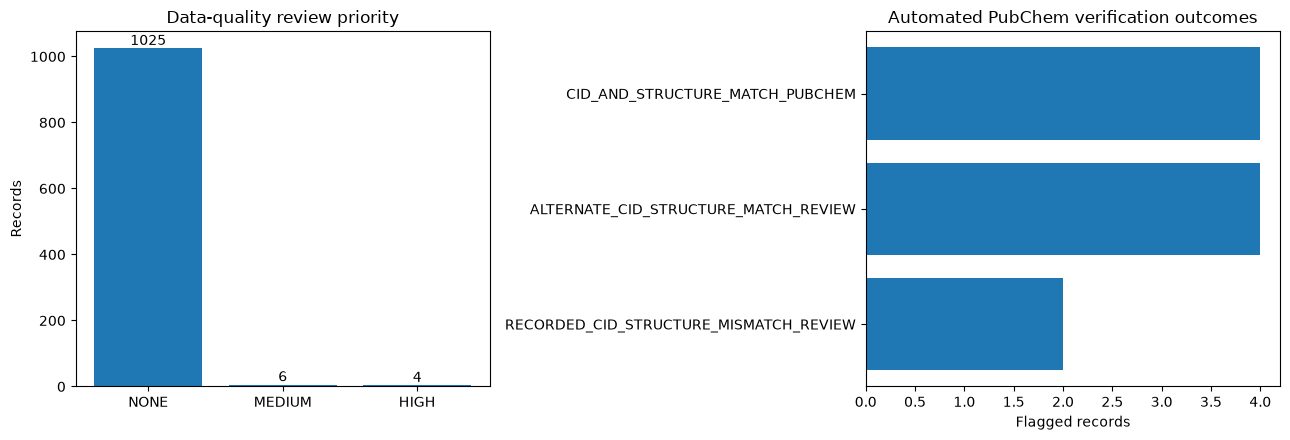

,name,recorded_CID,verification_status,next_action
0,Diclomezine (Ref: F-850),93341,CID_AND_STRUCTURE_MATCH_PUBCHEM,Check why CID is shared; original toxicity source not indepen...
1,Diflumetorim (Ref: UBF 002),93341,ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,Confirm alternate CID against original source; do not apply a...
2,Metiram (Ref: BAS 222F),5284484,RECORDED_CID_STRUCTURE_MISMATCH_REVIEW,Review CID-to-structure mapping and original record provenance
3,Zineb (Ref: ENT 14874),5284484,CID_AND_STRUCTURE_MATCH_PUBCHEM,Check why CID is shared; original toxicity source not indepen...
4,Chlormequat,13836,ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,Confirm alternate CID against original source; do not apply a...
5,"2-Chloro-N,N,N-trimethylethanaminium chloride (1:1)",13836,CID_AND_STRUCTURE_MATCH_PUBCHEM,Check why CID is shared; original toxicity source not indepen...
6,Silthiofam (Ref: MON 65500),16116,ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,Confirm alternate CID against original source; do not apply a...
7,N-(2-Methylcyclohexyl)-N'-phenylurea,16116,CID_AND_STRUCTURE_MATCH_PUBCHEM,Check why CID is shared; original toxicity source not indepen...
8,Metominostrobin (Ref: SSF 126),5483872,RECORDED_CID_STRUCTURE_MISMATCH_REVIEW,Review CID-to-structure mapping and original record provenance
9,Phthalide (Ref: BAY 96610),5483872,ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,Confirm alternate CID against original source; do not apply a...


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
priority_counts = audit["review_priority"].value_counts().reindex(["NONE", "MEDIUM", "HIGH"], fill_value=0)
axes[0].bar(priority_counts.index, priority_counts.values)
axes[0].set_title("Data-quality review priority")
axes[0].set_ylabel("Records")
for i, v in enumerate(priority_counts.values):
    axes[0].text(i, v, str(v), ha="center", va="bottom")

status_counts = verification_df["verification_status"].value_counts() if not verification_df.empty else pd.Series(dtype=int)
if len(status_counts):
    axes[1].barh(status_counts.index, status_counts.values)
    axes[1].invert_yaxis()
    axes[1].set_xlabel("Flagged records")
    axes[1].set_title("Automated PubChem verification outcomes")
else:
    axes[1].text(0.5, 0.5, "No flagged records", ha="center", va="center")
    axes[1].axis("off")
plt.tight_layout()
figure_file = AUDIT_DIR / "02_identity_audit_overview.png"
fig.savefig(figure_file, dpi=220, bbox_inches="tight")
plt.show()

# Even a positive PubChem identity match does not validate dataset toxicity labels.
review_needed = verification_df.copy()
if not review_needed.empty:
    review_needed["next_action"] = review_needed["verification_status"].map({
        "CID_AND_STRUCTURE_MATCH_PUBCHEM": "Check why CID is shared; original toxicity source not independently validated",
        "ALTERNATE_CID_STRUCTURE_MATCH_REVIEW": "Confirm alternate CID against original source; do not apply automatically",
        "SALT_OR_FRAGMENT_REVIEW": "Inspect full salt, counterion and charge representation",
        "MULTIPLE_STRUCTURE_MATCHES_REVIEW": "Resolve multiple matching PubChem records",
        "RECORDED_CID_STRUCTURE_MISMATCH_REVIEW": "Review CID-to-structure mapping and original record provenance",
        "API_UNAVAILABLE": "Retry when PubChem service/internet becomes available",
        "OFFLINE_NOT_QUERIED": "Enable PubChem and rerun",
        "NOT_FOUND_REVIEW": "Search authoritative alternative source",
        "INSUFFICIENT_PUBCHEM_EVIDENCE": "Compare original source and alternative identifiers",
        "INVALID_SMILES_REVIEW": "Repair only after checking primary chemical source"
    }).fillna("Manual source/provenance review required")
    display(review_needed[["name", "recorded_CID", "verification_status", "next_action"]])

## 10. Save fully automated, reproducible reports

Files are prefixed `02_` so your earlier Phase 02 reports are not silently overwritten. Live PubChem responses are cached separately. A human verification worksheet is no longer a prerequisite; `02_verification_review_queue.csv` is generated by code and prefilled with findings/evidence.

In [10]:
files_saved = {}
def export_csv(frame, filename):
    path = AUDIT_DIR / filename
    frame.to_csv(path, index=False, encoding="utf-8-sig")
    files_saved[filename] = str(path)

export_csv(audit, "02_full_chemical_identity_audit.csv")
export_csv(audit.loc[audit["review_priority"] != "NONE"], "02_flagged_records.csv")
export_csv(pairs, "02_repeated_cid_pair_comparison.csv")
export_csv(verification_df, "02_automated_pubchem_verification.csv")
export_csv(pair_verified, "02_pair_reconciliation.csv")
export_csv(review_needed, "02_verification_review_queue.csv")

summary = {
    "project": "BeeSafe AI — Phase 02",
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "dataset_path": str(DATA_PATH),
    "source_csv_sha256": source_checksum_before,
    "record_count": int(len(original_df)),
    "original_column_count": int(original_df.shape[1]),
    "invalid_smiles": int((~audit["valid_smiles"]).sum()),
    "repeated_cid_groups": int(audit.loc[audit["cid_repeated"], "CID_numeric"].nunique()),
    "flagged_rows": int(len(review_queue)),
    "high_priority_rows": int((audit["review_priority"] == "HIGH").sum()),
    "medium_priority_rows": int((audit["review_priority"] == "MEDIUM").sum()),
    "conflicting_cid_label_pairs": int(pairs.get("binary_label_conflict", pd.Series(dtype=bool)).sum()),
    "pubchem_live_enabled": bool(USE_PUBCHEM),
    "pubchem_results": {str(k):int(v) for k,v in status_counts.to_dict().items()},
    "uncorrected_toxicity_labels": True,
    "automatic_cid_edits": 0,
    "outcome": "AUDIT_COMPLETE_IDENTITIES_PENDING_EVIDENCE_REVIEW",
}

summary_file = AUDIT_DIR / "02_audit_summary.json"
summary_file.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
log_file = AUDIT_DIR / "02_pubchem_http_attempts.json"
log_file.write_text(json.dumps(http_log, indent=2), encoding="utf-8")

report_lines = [
    "# BeeSafe AI — Phase 02 Chemical Identity Audit",
    "",
    f"Generated UTC: {summary['generated_utc']}",
    f"Raw dataset SHA256: `{source_checksum_before}`",
    "",
    f"- Records examined: **{len(original_df)}**",
    f"- RDKit-invalid SMILES: **{summary['invalid_smiles']}**",
    f"- Repeated CID groups: **{summary['repeated_cid_groups']}**",
    f"- Records flagged for review: **{len(review_queue)}**",
    f"- High-priority records: **{summary['high_priority_rows']}**",
    f"- Conflicting CID-label pairs: **{summary['conflicting_cid_label_pairs']}**",
    f"- PubChem live querying enabled: **{USE_PUBCHEM}**",
    "", "## Automated verification results", ""
]
report_lines.extend(f"- {k}: {v} records" for k, v in status_counts.items())
report_lines += [
    "", "## Decisions and limits", "",
    "- No source rows, identifiers, or toxicity labels were changed.",
    "- A PubChem CID/structure match validates only the matched public structure identifier, not toxicity measurement quality.",
    "- Name/CAS lookup results can be ambiguous; alternate identifiers are suggestions, never automatic edits.",
    "- Salt and fragment equivalence requires explicit scientific review.",
    "- If the API was unavailable, corresponding verification remains incomplete.",
    "- See the source-linked CSV for the precise evidence for each flagged record.",
    "", "## References", "",
    "- https://pubchem.ncbi.nlm.nih.gov/docs/pug-rest",
    "- https://pubchem.ncbi.nlm.nih.gov/docs/pug-rest-tutorial",
]
(AUDIT_DIR / "02_research_audit_report.md").write_text("\n".join(report_lines), encoding="utf-8")

print("SAVED REPORTS:")
for filename, path in files_saved.items():
    print(" -", path)
print(" -", summary_file)
print(" -", log_file)
print(" -", figure_file)
print(" -", AUDIT_DIR / "02_research_audit_report.md")

SAVED REPORTS:
 - E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\chemical_identity_audit\02_full_chemical_identity_audit.csv
 - E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\chemical_identity_audit\02_flagged_records.csv
 - E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\chemical_identity_audit\02_repeated_cid_pair_comparison.csv
 - E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\chemical_identity_audit\02_automated_pubchem_verification.csv
 - E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\chemical_identity_audit\02_pair_reconciliation.csv
 - E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\chemical_identity_audit\02_verification_review_queue.csv
 - E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\chemical_identity_audit\02_audit_summary.json
 - E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\chemical_identity_audit\02_pubchem_http_attempts.json
 - E:\CODE\Python\AL

## 11. Final integrity checks and research sign-off

A successful *execution* means the analysis and automatic lookups ran and reports were generated. It does **not** imply that every problematic chemical identity is resolved. The next stage should use a **documented, evidence-based feature-preparation policy** and avoid mixing candidate duplicates across train/test splits.

In [11]:
source_checksum_after = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert source_checksum_before == source_checksum_after, "Raw dataset checksum changed!"
assert original_df.shape == (len(audit), len(original_df.columns))
assert audit["source_row_index"].nunique() == len(original_df)
assert len(verification_df) == len(review_queue)
assert set(audit["review_priority"].unique()).issubset({"NONE", "MEDIUM", "HIGH"})

print("=" * 68)
print("BEESAFE AI — PHASE 02 AUTOMATED AUDIT FINISHED")
print("=" * 68)
print("Source CSV unchanged:", source_checksum_before == source_checksum_after)
print("Records checked:", len(original_df))
print("Flagged records:", len(review_queue))
print("Live PubChem enabled:", USE_PUBCHEM)
print("API outcome counts:", dict(status_counts))
print("Original label/CID edits performed: 0")
print("Reports:", AUDIT_DIR)
print("\nNEXT: Evaluate review queue and source evidence before Phase 03.")

BEESAFE AI — PHASE 02 AUTOMATED AUDIT FINISHED
Source CSV unchanged: True
Records checked: 1035
Flagged records: 10
Live PubChem enabled: True
API outcome counts: {'CID_AND_STRUCTURE_MATCH_PUBCHEM': np.int64(4), 'ALTERNATE_CID_STRUCTURE_MATCH_REVIEW': np.int64(4), 'RECORDED_CID_STRUCTURE_MISMATCH_REVIEW': np.int64(2)}
Original label/CID edits performed: 0
Reports: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\chemical_identity_audit

NEXT: Evaluate review queue and source evidence before Phase 03.
